# Housing Conditions in Canada Analysis

## Data set Introduction - Housing Conditions in Canada Analysis

I found this data set via Statistics Canada from the period 2021-2022.

The reason I chose this is to get a deeper understanding on people living in acceptable housing versus not living in acceptable housing, based on factors such as location, housing tenure, and year. The dataset is mostly metadata and government referencing, but with the columns left over after dropping unimportant columns we can still uncover patterns with the deciding columns. 

This dataset comes from the Canadian Housing Survey, which collects information from households and produces summarized statistics. The values in the dataset are already aggregated percentages rather than raw individual-level data.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Import your helper module
import sys
sys.path.insert(0, '..')
from src.helpers import *

In [3]:
import pandas as pd
df = pd.read_csv('../data/housing2022.csv')

# What is acceptable housing?

The definition of acceptable housing is based on Statistics Canada's criteria, which include affordability, adequacy, and suitability.

**Affordability** refers to whether housing costs are reasonable relative to a household’s income. \
**Adequacy** refers to the physical condition of the home, such as whether it requires major repairs. \
**Suitability** refers to whether the housing has enough space for the people living in it.

For housing to be considered acceptable, it must meet all three of these conditions. If a household fails to meet even one of them, it is classified as living in unacceptable housing.

# Initial Exploration 

In [4]:
df.shape

(364, 17)

### `df.shape` 

Using `df.shape`, I can see that the dataset has 364 rows and 17 columns.

At first, 364 rows seems small for data that represents all of Canada, but this makes sense after considering that the dataset is aggregated. Each row represents a combination of factors like region, tenure, housing status, and year, rather than individual people.

Because of this, the dataset is smaller but still useful. Instead of analyzing individuals, the focus will be on comparing patterns between groups.

In [5]:
df.head()

,REF_DATE,GEO,DGUID,Tenure including first-time homebuyer and social and affordable housing status,Acceptable housing,Statistics,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
0,2021,Canada (excluding territories),2021A000011124,"Total, by tenure",Does not live in acceptable housing,Percentage of persons,Percent,239,units,0,v1544264166,1.1.1.1,29.0,NaN,NaN,NaN,1
1,2022,Canada (excluding territories),2021A000011124,"Total, by tenure",Does not live in acceptable housing,Percentage of persons,Percent,239,units,0,v1544264166,1.1.1.1,31.0,NaN,NaN,NaN,1
2,2021,Canada (excluding territories),2021A000011124,"Total, by tenure",Lives in acceptable housing,Percentage of persons,Percent,239,units,0,v1544264172,1.1.11.1,71.0,NaN,NaN,NaN,1
3,2022,Canada (excluding territories),2021A000011124,"Total, by tenure",Lives in acceptable housing,Percentage of persons,Percent,239,units,0,v1544264172,1.1.11.1,69.0,NaN,NaN,NaN,1
4,2021,Canada (excluding territories),2021A000011124,Owner household,Does not live in acceptable housing,Percentage of persons,Percent,239,units,0,v1544264232,1.2.1.1,22.0,NaN,NaN,NaN,1


In [6]:
df['UOM'].unique()

array(['Percent'], dtype=object)

In [7]:
df['SCALAR_FACTOR'].unique()

array(['units'], dtype=object)

In [8]:
df['SCALAR_ID'].unique()

array([0])

**`df['UOM'].unique()`** confirms that `UOM` column only contains the value "Percent". Since this value doesn't change, it is not necessary to keep for analysis. I also checked `SCALAR_FACTOR`, `SCALAR_ID`, `UOM_ID`, `STATISTICS`, and `DECIMAL`, the result was the same. The value was the same throughtout the dataset, so no need to keep the columns for further analysis.  

In [9]:
df['STATUS'].isna().sum()

np.int64(364)

**df['STATUS'].isna().sum()** produces the result that every row for `STATUS` is NaN, so this confirms it is not suitable to keep for analysis as it has no significance because it is the same through out. This is also the case for `SYMBOL` and `TERMINATED`

In [10]:
df['DGUID'].nunique()

13

In [11]:
df['COORDINATE'].nunique()

182

To check if columns like `DGUID` were useful, I ran **`df['DGUID'].nunique()`** to see how many unique values it contains. The result was **13**, which matches the number of regions in the dataset.

This suggests that `DGUID` acts as an identifier for each region rather than providing new analytical information. Since it does not add meaningful insight beyond labeling regions, it was removed during the cleaning process.

I also used this method to check `VECTOR` and `COORDINATE` and the results were the **182 unique values** which is half of **364** (rows in dataset), so this suggests that these columns are for each year and are also used for reference only and provide no insight for analysis.

## `df.head()`
---

I used `df.head()` to view the first few rows of the dataset and understand its structure.

From this preview and the above further analysis, I concluded that the dataset contains both useful variables and metadata. Columns such as `Statistics`, `UOM`, `DGUID`, `VECTOR`, `COORDINATE`, `STATUS`, and `SYMBOL` are metadata used by Statistics Canada for organization and reference, rather than analysis.


Based on the dataset documentation:
- **DGUID**: geographic identifier  
- **VECTOR**: internal table reference code  
- **COORDINATE**: position in the data table  
- **UOM / SCALAR**: units and scaling of values  
- **STATUS / SYMBOL**: data quality indicators  

Since these columns do not contribute meaningful analytical information, they were removed to simplify the dataset.

The key variables used for analysis are:
- `REF_DATE`: year of data collection  
- `GEO`: region  
- `Tenure`: type of housing (owner or renter)  
- `Acceptable Housing`: whether housing is acceptable  
- `VALUE`: percentage of people in each group  

These variables allow for comparison of housing conditions across regions, tenure types, and time.


In [12]:
df.value_counts('GEO')

GEO
Alberta                           28
Atlantic Region                   28
British Columbia                  28
Canada (excluding territories)    28
Manitoba                          28
New Brunswick                     28
Newfoundland and Labrador         28
Nova Scotia                       28
Ontario                           28
Prairies Region                   28
Prince Edward Island              28
Quebec                            28
Saskatchewan                      28
Name: count, dtype: int64

## Looking Deeper into Regions

To better understand how the dataset is structured, I examined the number of rows for each region using `df.value_counts('GEO')` and by filtering to only look at "Manitoba"(code below).

From this, I noticed that every region consistently contains 28 rows. This pattern suggested that the data is not random, but organized into specific combinations.

Looking more closely, I found that each region includes:
- 7 tenure categories  
- 2 housing statuses (Acceptable and Not Acceptable)  
- 2 years  

When these are combined (7 × 2 × 2), they result in 28 unique combinations per region. This shows that each row represents a specific grouping of year, tenure, and housing status, rather than individual observations.

In [13]:
df[df["GEO"] == "Manitoba"][[
    "REF_DATE",
    "GEO",
    "Tenure including first-time homebuyer and social and affordable housing status",
    "Acceptable housing",
    "VALUE"
]]

,REF_DATE,GEO,Tenure including first-time homebuyer and social and affordable housing status,Acceptable housing,VALUE
252,2021,Manitoba,"Total, by tenure",Does not live in acceptable housing,29.0
253,2022,Manitoba,"Total, by tenure",Does not live in acceptable housing,28.0
254,2021,Manitoba,"Total, by tenure",Lives in acceptable housing,71.0
255,2022,Manitoba,"Total, by tenure",Lives in acceptable housing,72.0
256,2021,Manitoba,Owner household,Does not live in acceptable housing,23.0
257,2022,Manitoba,Owner household,Does not live in acceptable housing,21.0
258,2021,Manitoba,Owner household,Lives in acceptable housing,77.0
259,2022,Manitoba,Owner household,Lives in acceptable housing,79.0
260,2021,Manitoba,"Owner household, first-time homebuyer",Does not live in acceptable housing,18.2
261,2022,Manitoba,"Owner household, first-time homebuyer",Does not live in acceptable housing,24.0


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 364 entries, 0 to 363
Data columns (total 17 columns):
 #   Column                                                                          Non-Null Count  Dtype  
---  ------                                                                          --------------  -----  
 0   REF_DATE                                                                        364 non-null    int64  
 1   GEO                                                                             364 non-null    object 
 2   DGUID                                                                           364 non-null    object 
 3   Tenure including first-time homebuyer and social and affordable housing status  364 non-null    object 
 4   Acceptable housing                                                              364 non-null    object 
 5   Statistics                                                                      364 non-null    object 
 6   UOM               

### `df.info()` 

Running `df.info()` gave a clearer picture of the dataset’s overall structure. It shows that the dataset contains 17 columns and 364 rows, along with the data types for each column.

From this output, I observed three main data types: `float64` (decimal values), `int64` (integers), and `object` (text-based data). This helps confirm what kind of information each column holds.

A key observation was that the `STATUS`, `SYMBOL`, and `TERMINATED` columns all contain 0 non-null values. This means they do not hold any usable data in this dataset, which further supports the decision to remove them during the cleaning process.

This step helped confirm both the structure of the dataset and which columns were unnecessary for analysis.


In [15]:
df.describe()

,REF_DATE,UOM_ID,SCALAR_ID,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
count,364.000000,364.0,364.0,364.000000,0.0,0.0,0.0,364.0
mean,2021.500000,239.0,0.0,50.000000,NaN,NaN,NaN,1.0
std,0.500688,0.0,0.0,22.118484,NaN,NaN,NaN,0.0
min,2021.000000,239.0,0.0,10.900000,NaN,NaN,NaN,1.0
25%,2021.000000,239.0,0.0,30.000000,NaN,NaN,NaN,1.0
50%,2021.500000,239.0,0.0,50.000000,NaN,NaN,NaN,1.0
75%,2022.000000,239.0,0.0,70.000000,NaN,NaN,NaN,1.0
max,2022.000000,239.0,0.0,89.100000,NaN,NaN,NaN,1.0


### `df.describe()`
When we run `df.describe()` we are only running the intergers and float data types, and honestly the only one worth looking at is `VALUE` as this number represents our predicting column. All other columns are ones I plan to drop, besides the `REF_DATE` but running `describe()` on a date has no significance, other than our dataset spans from 2021-2022.

`VALUE` percentage of people in acceptable or unacceptable housing 

- min of 10.9 %
- max of 89.1%
- avg of 50%
- The wide range in values suggests that housing conditions vary significantly depending on location and tenure.
- The standard deviation (22.1) indicates a relatively high level of variability in housing conditions across the dataset.
- Columns such as `UOM_ID`, `SCALAR_ID`, and `DECIMALS` have constant values, further evidence to drop the columns later.


# Analytical Questions

1. Do renters experience a higher percentage of unacceptable housing compared to homeowners?

2. Which provinces have the highest and lowest percentages of people living in unacceptable housing?

3. How have housing conditions changed between 2021 and 2022 across different regions?

4. How do housing conditions differ between first-time homebuyers and non-first-time homeowners?


### Observations

1. The dataset contains 364 rows and 17 columns, indicating a moderately sized dataset suitable for analysis.

2. The data includes information for two years, 2021 and 2022, which allows for basic comparison over time.

3. The dataset includes multiple categories of housing tenure, such as owners, renters, and first-time homebuyers.

4. The dataset will be reduced in columns, but there is many comparisons to make from how much information is in each column.

5. The values are represented as percentages, making it easier to compare housing conditions across different groups.

6. Several columns (such as DGUID, VECTOR, and COORDINATE) appear to be metadata and do not contribute meaningful information for analysis.

# Cleaning the Dataset

### Clean column names
I standarized column names to ensure consistency and make them easier to read and work with during analysis. 

### Drop unnecessary columns
When I looked over the dataset for the first time, I right away noticed that most of the columns were not needed, as they were for government reference and metadata that will not add anything to the analysis. So we drop them from our cleaned dataset. This will get rid of anything we don't need to see.

### Rename columns
Now for the next cleaning step, I want to rename the remaining column names into more user friendly names by creating a dictionary in the `helpers.py` folder. For example, "Ref Date" to "Year" is easier to understand.

### Simplify Tenure category values
I am going to simplify the names in the Tenure column, as the original titles are too long and having them shorter will be best for later visualization.


### Make Tenure Group
I am going to make another group for Tenure to keep valuable information such as if they are first time buyer or on social assistance, because I think this could be interesting to compare with each other. \
I will simplify the groups so we can do analysis on three simple groups as well as the more detailed Tenure.

### Simplify Housing status values
I simplified the housing status labels by shortening the long descriptions to easier shorter names. "Does not live in acceptable housing" now simply becomes "Not Acceptable". This will improve readability for our future analysis.

In [16]:
df_cleaned = clean_column_names(df)
df_cleaned = drop_metadata_columns(df_cleaned)
df_cleaned = rename_columns(df_cleaned)
df_cleaned = add_tenure_group(df_cleaned)
df_cleaned = simplify_tenure(df_cleaned)
df_cleaned = simplify_housing_status(df_cleaned)
df_provinces = filter_provinces(df_cleaned)
df_cleaned.columns

Index(['Year', 'Region', 'Tenure', 'Housing Status', 'Percentage',
       'Tenure Group'],
      dtype='object')

In [17]:
df_cleaned

,Year,Region,Tenure,Housing Status,Percentage,Tenure Group
0,2021,Canada (excluding territories),Total,Not Acceptable,29.0,Total
1,2022,Canada (excluding territories),Total,Not Acceptable,31.0,Total
2,2021,Canada (excluding territories),Total,Acceptable,71.0,Total
3,2022,Canada (excluding territories),Total,Acceptable,69.0,Total
4,2021,Canada (excluding territories),Owner,Not Acceptable,22.0,Owner
...,...,...,...,...,...,...
359,2022,British Columbia,Renter (Non-social),Acceptable,49.0,Renter
360,2021,British Columbia,Renter (Social),Not Acceptable,41.0,Renter
361,2022,British Columbia,Renter (Social),Not Acceptable,48.0,Renter
362,2021,British Columbia,Renter (Social),Acceptable,59.0,Renter


### Cleaning Complete

After working through the cleaning steps, the dataset became much simpler and easier to understand. Removing the unnecessary metadata columns helped reduce clutter and made it clearer which variables are actually useful for analysis.

I also standardized the column names to keep everything consistent, and simplified some of the category values so they are easier to read and compare. In addition, I created a new column to group tenure values, which will help when comparing broader patterns.

With these changes, the dataset is now more organized and ready to be used for further analysis.

---

# Visualizations to answer Analytical Questions

---

## Question 1: Do renters experience a higher percentage of unacceptable housing compared to homeowners?

Let's begin with the first question, I want to compare housing conditions between renters and homeowners. Since these groups represent different housing situations, this comparison will allow us to visualize if one group is more likely to have acceptable housing or not.


<function matplotlib.pyplot.show(close=None, block=None)>

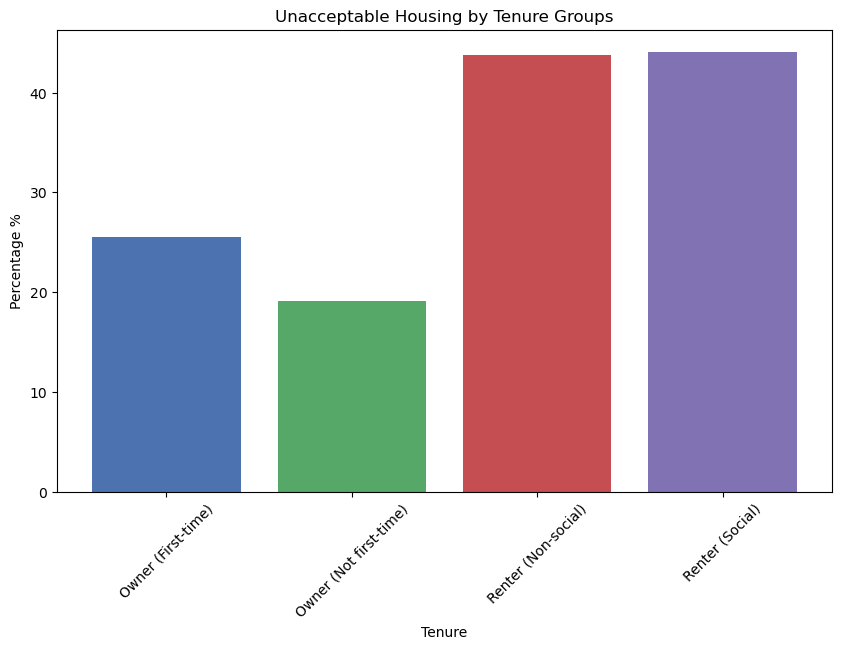

In [18]:
# we only want one group so we filter to "not acceptable"
unacceptable = df_cleaned[df_cleaned["Housing Status"] == "Not Acceptable"]

unacceptable = unacceptable[
    unacceptable["Tenure"].isin([
        "Owner (First-time)",
        "Owner (Not first-time)",
        "Renter (Social)",
        "Renter (Non-social)"
    ])
]

# remove total
tenure_unacceptable = unacceptable.groupby("Tenure")["Percentage"].mean()

# create plot
fig, ax = plt.subplots(figsize=(10, 6))

# nice different colours
colours = ["#4c72b0", "#55a868", "#c44e52", "#8172b3"]
ax.bar(tenure_unacceptable.index, tenure_unacceptable.values, color = colours)

# labels
ax.set_title("Unacceptable Housing by Tenure Groups")
ax.set_xlabel("Tenure")
ax.set_ylabel("Percentage %")
ax.tick_params(axis = 'x', rotation = 45)

plt.show

### Bar plot - Unacceptable housing percentages

When we look at this chart, the difference between renters and homeowners is clear. Renters are much more likely to live in unacceptable housing compared to homeowners.

Homeowners have lower percentages of unacceptable housing, generally around the 20–25% range. In contrast, all renter categories are significantly higher, with values above 40%. This pattern remains consistent even when renters are divided into social and non-social groups.

An important observation is that none of the renter groups overlap with homeowner levels. This shows a clear separation between the two, suggesting that tenure plays a major role in housing quality.

These results indicate that renters consistently experience higher rates of unacceptable housing than homeowners. This comparison is based on overall averages and does not account for regional differences.

To explore this further, the next step is to examine whether this pattern holds across different provinces and determine if housing conditions vary by region.

### Grouped Bar chart - renters vs homeowners within each region

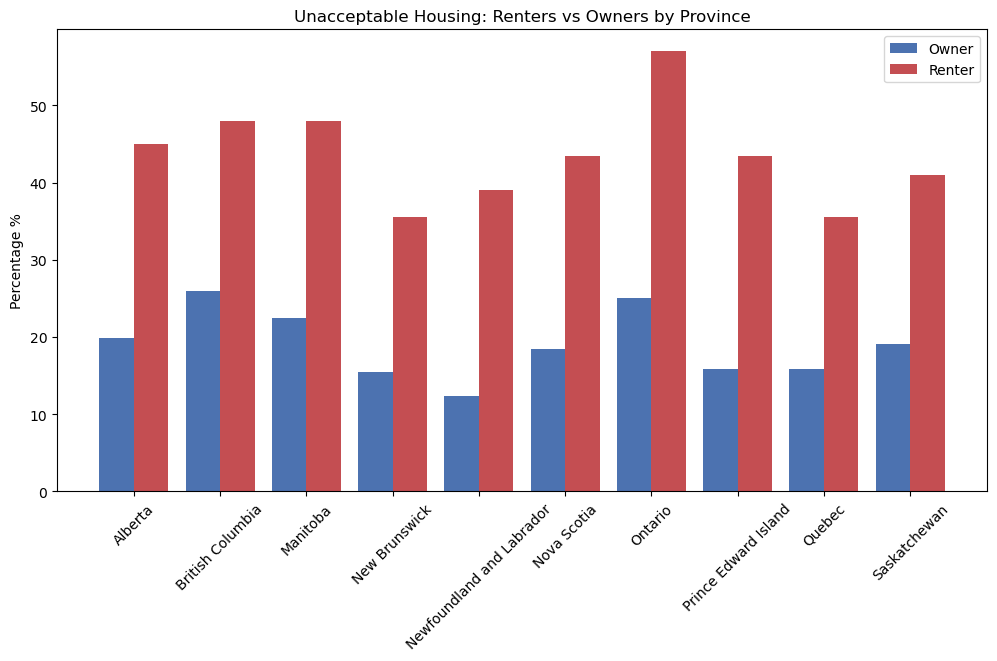

In [19]:
# filter to only unacceptable housing
subset = df_provinces[
    (df_provinces["Housing Status"] == "Not Acceptable") &

    # keep only the two groups we want to compare
    (df_provinces["Tenure"].isin([
        "Owner (Not first-time)",
        "Renter (Non-social)"
    ]))
]

# reshape data so Owner and Renter become columns
pivot = subset.pivot_table(
    index = "Region",        # rows = provinces
    columns = "Tenure",      # columns = Owner vs Renter
    values = "Percentage",   # values to compare
    aggfunc = "mean"         # take average if needed
)

# create x positions for each province
regions = pivot.index
x = np.arange(len(regions))

# create plot
fig, ax = plt.subplots(figsize=(12, 6))

# owner bars (shifted left)
ax.bar(x - 0.2, pivot["Owner (Not first-time)"], 
       width = 0.4, label = "Owner", color = "#4c72b0")

# renter bars (shifted right)
ax.bar(x + 0.2, pivot["Renter (Non-social)"], 
       width = 0.4, label = "Renter", color = "#c44e52")

# set province labels
ax.set_xticks(x)
ax.set_xticklabels(regions, rotation = 45)

# labels and title
ax.set_ylabel("Percentage %")
ax.set_title("Unacceptable Housing: Renters vs Owners by Province")

# legend
ax.legend()

# show plot
plt.show()

# What does this show?

Comparing renters and homeowners within each province

This comparison shows that renters have higher rates of unacceptable housing in every province. The size of the gap varies, with provinces like Ontario showing much larger differences, while Quebec and New Brunswick have smaller gaps, the gaps are still quite large.

This suggests that although the pattern is consistent across regions, the level of inequality remains high in all provinces.

This matters because it shows that renters are consistently more affected by unacceptable housing, and that the issue is widespread rather than limited to specific regions. The large gaps across all provinces suggest that factors affecting renters may play a major role in housing inequality, and further investigation would be needed to understand the underlying causes.

## Question 2: Which provinces have the highest and lowest percentages of people living in acceptable housing?

To answer this question, I want to compare percentages of people living in unacceptable housing across different regions. This helps identify which provinces experience the highest and lowest housing challenges.

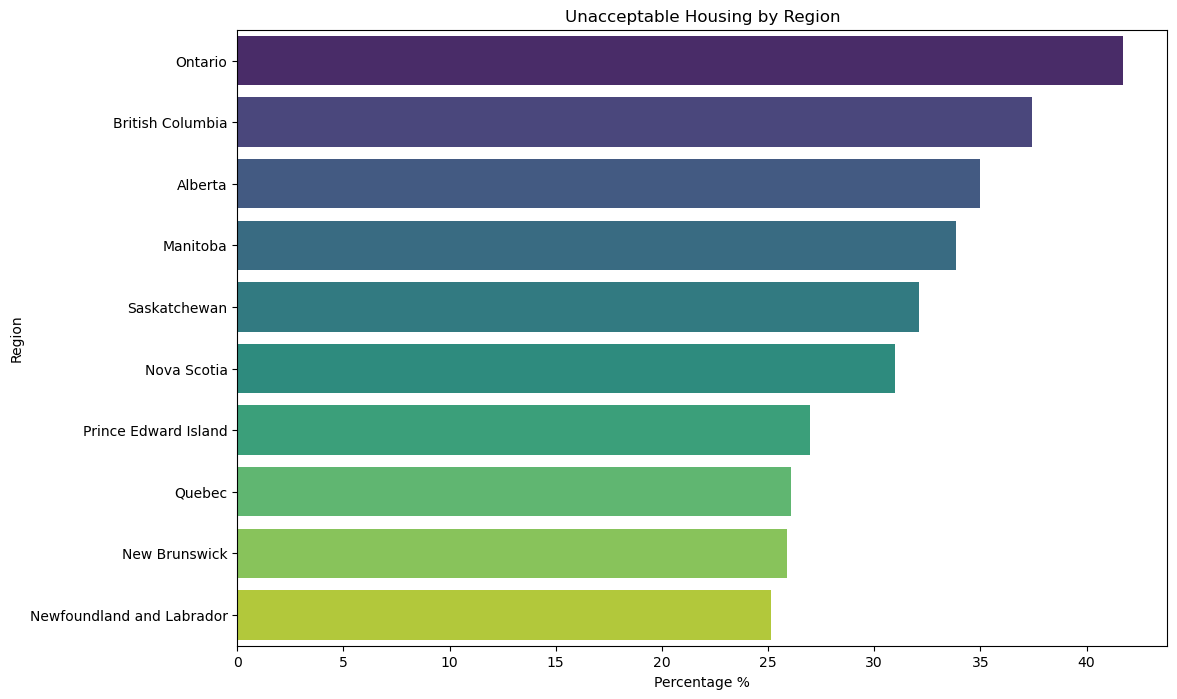

In [20]:
# filter to only unacceptable housing with new helper

unacceptable = df_provinces[df_provinces["Housing Status"] == "Not Acceptable"]

# Group by region and calculate average
region_unacceptable = unacceptable.groupby("Region")["Percentage"].mean()

# sort values 
region_unacceptable = region_unacceptable.sort_values(ascending = False)

# convert to Dataframe using Seaborn
region_unacceptable = region_unacceptable.reset_index()

# create plot

fig, ax = plt.subplots(figsize = (12, 8))

sns.barplot(
    data = region_unacceptable,
    x = "Percentage",
    y = "Region",
    hue = "Region",
    ax = ax,
    palette = "viridis",
    legend = False
)

# labels
ax.set_title("Unacceptable Housing by Region")
ax.set_xlabel("Percentage %")
ax.set_ylabel("Region")

plt.show()



### Horizontal Bar Chart - Unacceptable housing across Canada

The chart shows clear differences in unacceptable housing across provinces. Ontario has the highest percentage, while Newfoundland and Labrador has the lowest. Other provinces, such as British Columbia and Alberta, also show relatively high levels.

The differences between provinces are not extreme, and most regions fall within a similar range. This suggests that while housing challenges vary by location, no province is completely unaffected.

This comparison only shows overall levels and does not explain what is driving these differences. For example, higher percentages in some provinces may be influenced by renter conditions rather than homeowner conditions.

This indicates that regional differences exist, but further analysis is needed to understand the underlying causes of these patterns.

While this comparison highlights regional differences, it does not explain what is causing them. Later in the analysis, I examine the gap between renters and homeowners to better understand how tenure may be influencing these patterns.

## Question 3: How have housing conditions changed between 2021 and 2022 across different regions?

To answer this question, I compare the percentage of people living in unacceptable housing between 2021 and 2022 for each region. A grouped bar chart is used to clearly show the differences between the two years.

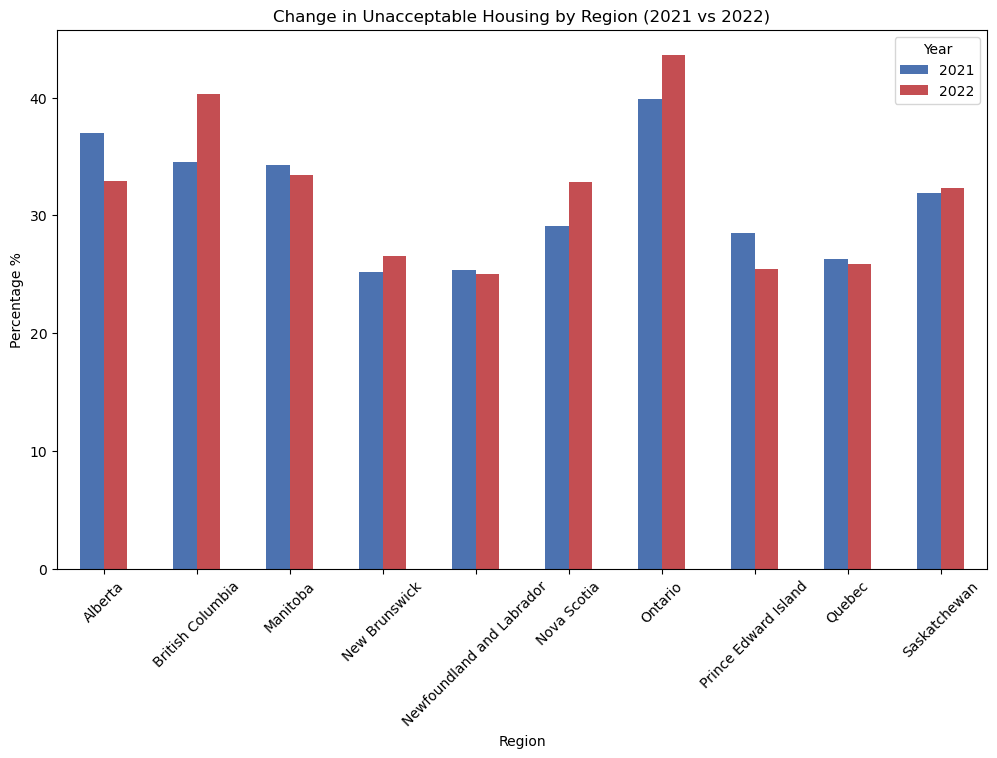

In [21]:
# filter to unacceptable housing
unacceptable = df_provinces[df_provinces["Housing Status"] == "Not Acceptable"]

# group data
trend = unacceptable.groupby(["Region", "Year"])["Percentage"].mean().unstack()

# plot
fig, ax = plt.subplots(figsize = (12, 7))

trend.plot(
    kind = "bar",
    ax = ax,
    color = ["#4c72b0", "#c44e52"]
)

# labels
ax.set_title("Change in Unacceptable Housing by Region (2021 vs 2022)")
ax.set_xlabel("Region")
ax.set_ylabel("Percentage %")
ax.legend(title = "Year")

plt.xticks(rotation = 45)
plt.show()

### Grouped Bar Chart – How does unacceptable housing change between 2021 and 2022?

This grouped bar chart shows how unacceptable housing differs between 2021 to 2022. 

I notice that some provinces have an increase in unacceptable housing like British Columbia, Ontario, and Nova Scotia. While Alberta and Prince Edward Island have the highest decrease in unacceptable housing. And all other provinces have little change between the years.

This analysis is important because it helps to see which provinces need more attention in getting their unacceptable housing percentages down and which ones are improving their housing, to uncover why we would need more data on the provinces, like income and area in the province would help future analysis by trying to uncover what is driving unacceptable housing.


# Focus on Prince Edward Island and Quebec
These two provinces have the largest decrease in unacceptable housing as seen in the grouped bar chart above. \
In the line chart below we will compare each province side by side to with all four tenure groups vs. unacceptable housing and compare the results.

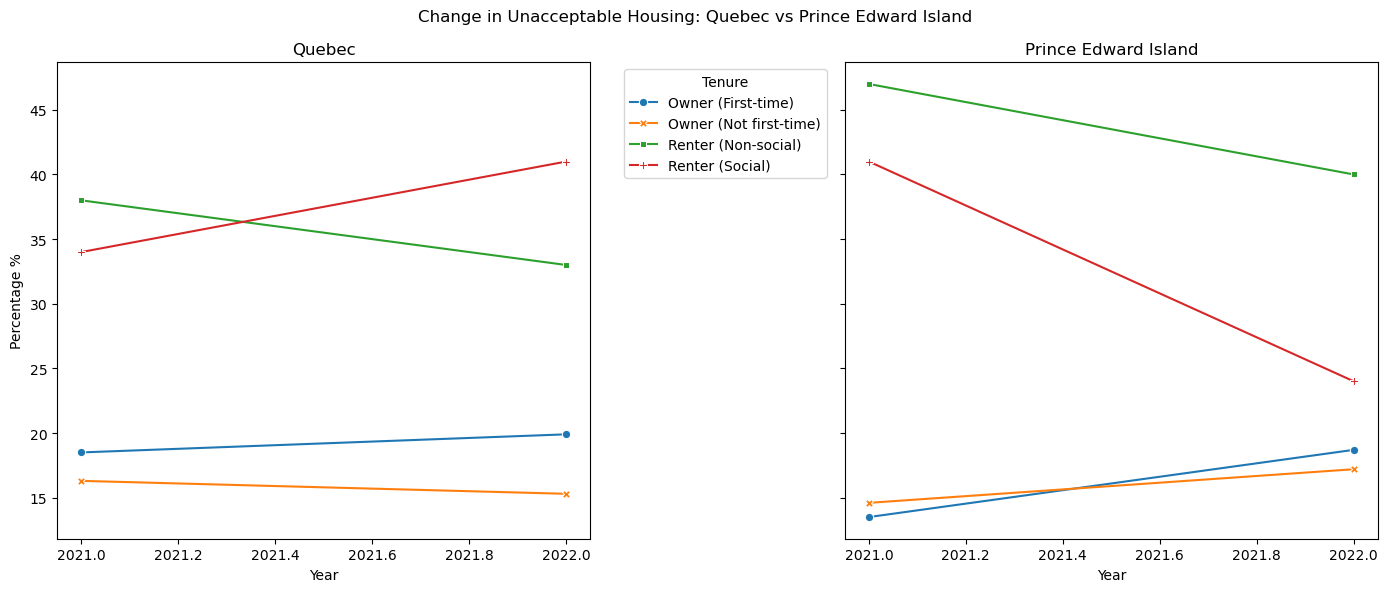

In [22]:
province1 = "Quebec"
province2 = "Prince Edward Island"

subset = df_provinces[
    (df_provinces["Region"].isin([province1, province2])) &
    (df_provinces["Housing Status"] == "Not Acceptable")
]

subset = subset[
    subset["Tenure"].isin([
        "Owner (First-time)",
        "Owner (Not first-time)",
        "Renter (Social)",
        "Renter (Non-social)"
    ])
]

# create two plots side by side
fig, axes = plt.subplots(1, 2, figsize = (14, 6), sharey = True)

# Quebec plot
quebec_data = subset[subset["Region"] == province1]

sns.lineplot(
    data=quebec_data,
    x = "Year",
    y = "Percentage",
    hue = "Tenure",
    style = "Tenure",
    markers = True,
    dashes = False,
    ax = axes[0]
)

axes[0].set_title("Quebec")
axes[0].set_ylabel("Percentage %")

# PEI plot
pei_data = subset[subset["Region"] == province2]

sns.lineplot(
    data = pei_data,
    x = "Year",
    y = "Percentage",
    hue = "Tenure",
    style = "Tenure",
    markers = True,
    dashes = False,
    ax = axes[1]
)

axes[1].set_title("Prince Edward Island")
axes[1].set_ylabel("")

# remove second legend
axes[1].get_legend().remove()

# move legend
axes[0].legend(title = "Tenure", bbox_to_anchor = (1.05, 1), loc = 'upper left')

plt.suptitle("Change in Unacceptable Housing: Quebec vs Prince Edward Island")
plt.tight_layout()
plt.show()

## Comparing Quebec and Prince Edward Island

One thing that stands out is how much renter housing improves in Prince Edward Island. Both renter groups decrease, especially social renters, which drop by almost 17 percentage points. At the same time, both homeowner groups show small increases in unacceptable housing, but their values remain much lower overall.

This matters because it shows that improvements in housing conditions are possible, and that changes in renter conditions can have a large impact on overall housing quality in a region.

In Quebec, the pattern is different. The renter groups move in opposite directions, with non-social renters decreasing while social renters increase. This suggests that improvements are not consistent across renter groups. 

Overall, this comparison shows that renter housing conditions play a major role in changes in unacceptable housing. When renter rates decrease significantly, overall housing conditions improve, but when renter groups move in different directions, the overall trend is less clear.

# 4. Explaining Regional Differences in Housing Inequality

While renters have higher rates of unacceptable housing overall, this pattern is not the same across all provinces. To explore this, I compare the gap between renters and homeowners across regions.

Rather than comparing values directly, this chart focuses on the size of the difference between renters and homeowners.

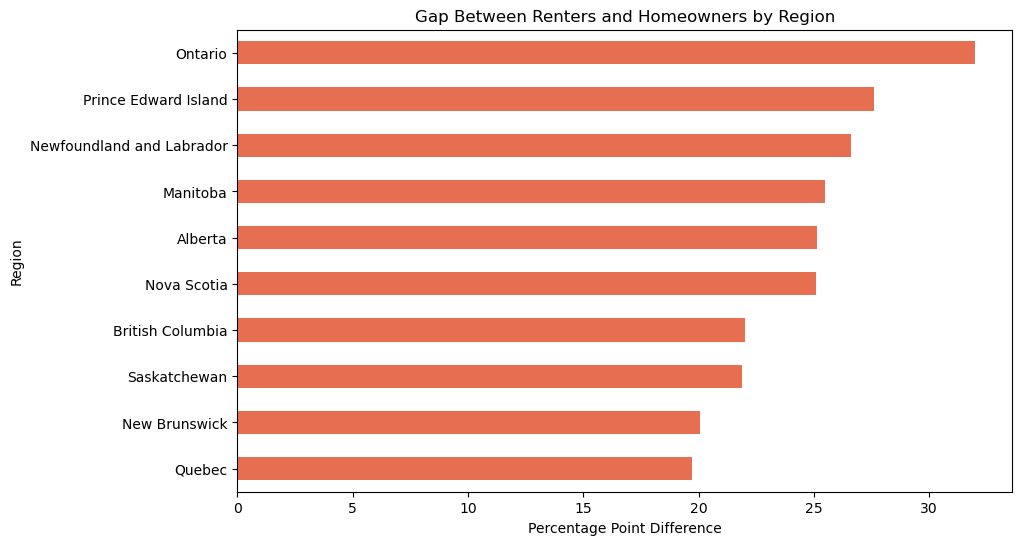

In [23]:
subset = df_provinces[
    df_provinces["Housing Status"] == "Not Acceptable"
]

# focus owner and renter types
subset = subset[
    subset["Tenure"].isin([
        "Owner (Not first-time)",
        "Renter (Non-social)"
    ])
]

# reshape data with pivot table so we can subtract
pivot = subset.pivot_table(
    index = "Region",
    columns = "Tenure",
    values = "Percentage",
    aggfunc = "mean"
)

# compute gap
pivot["Gap (Renter - Owner)"] = pivot["Renter (Non-social)"] - pivot["Owner (Not first-time)"]

gap = pivot["Gap (Renter - Owner)"].sort_values(ascending=True)

# plot
fig, ax = plt.subplots(figsize = (10, 6))

gap.plot(kind = "barh", ax = ax, color = "#e76f51")

ax.set_title("Gap Between Renters and Homeowners by Region")
ax.set_xlabel("Percentage Point Difference")
ax.set_ylabel("Region")

plt.show()

## Observation on gap
Provinces such as Ontario have the largest gaps, indicating a much greater difference between renters and homeowners. In contrast, Quebec and New Brunswick show smaller gaps, suggesting less disparity between the two groups.


In [24]:
gap_table = pivot[["Renter (Non-social)", "Owner (Not first-time)"]].copy()

gap_table["Difference"] = gap_table["Renter (Non-social)"] - gap_table["Owner (Not first-time)"]

# sort from highest to lowest
gap_table = gap_table.sort_values(by = "Difference", ascending = False)

gap_table.round(2)

Tenure,Renter (Non-social),Owner (Not first-time),Difference
Region,,,
Ontario,57.0,25.00,32.00
Prince Edward Island,43.5,15.90,27.60
Newfoundland and Labrador,39.0,12.40,26.60
Manitoba,48.0,22.50,25.50
Alberta,45.0,19.85,25.15
Nova Scotia,43.5,18.40,25.10
British Columbia,48.0,26.00,22.00
Saskatchewan,41.0,19.10,21.90
New Brunswick,35.5,15.45,20.05


## Look at each province, renter(non-social) vs. Owner(not first time)

Looking at the pivot table, Ontario has the largest difference between renters and homeowners, but the gap is noticeable across all provinces.

This shows that renters are consistently worse off in every region. More importantly, the size of the gap is mainly driven by the percentage of renters living in unacceptable housing. These percentages are not only higher than those of homeowners, but they also vary more across provinces, while homeowner values remain relatively stable.

This matters because it shows that changes in renter housing conditions have the biggest impact on overall housing inequality. Provinces with higher renter percentages tend to have much larger gaps, meaning that improving renter housing conditions could significantly reduce inequality.

---

# Prediction - Can housing characteristics help predict the percentage of people living in unacceptable housing?

To add a simple predictive model, I will use linear regression to predict the `Percentage` column based on year, region, tenure, and housing status. Since the target is numeric, linear regression is a suitable first model for this dataset.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

df_model = df_provinces.copy()

# remove total
df_model = df_model.drop(
    df_model[df_model["Tenure"] == "Total"].index)

# drop extra column
df_model = df_model.drop(columns=["Tenure Group"], errors="ignore")

# convert to numbers
df_model = pd.get_dummies(
    df_model,
    columns=["Region", "Tenure", "Housing Status"],
    drop_first=True
)

# split
X = df_model.drop("Percentage", axis=1)
y = df_model["Percentage"]

# split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# create and fit model
model = LinearRegression()
model.fit(X_train, y_train)

# predictions
y_pred = model.predict(X_test)

# evaluation
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R²:", r2)

RMSE: 14.489476657208554
R²: 0.5296725973487908


# Model performance 

### Prediction Results

I used linear regression to predict the `Percentage` based on region, tenure, housing status, and year.

The model gave an RMSE of about 14.5, meaning predictions are off by around 14 percentage points on average. The $R^2$ value is 0.53, so the model explains about half of the variation in the data.

This shows the model is picking up some patterns, but it’s not very accurate. That makes sense since the dataset is small and aggregated, and doesn’t include other factors that affect housing conditions.

The model works as a simple example, but it isn’t strong enough for precise predictions.

---

# Final Conclusion

From this analysis, I found that renters consistently experience higher rates of unacceptable housing compared to homeowners, although the size of this difference varies across provinces. Ontario shows the highest levels, while Newfoundland and Labrador has the lowest. These differences are mainly driven by renter housing conditions, while homeowner values remain more stable. I also observed that first-time homeowners tend to have outcomes closer to renters than to more established homeowners.

One surprising finding was how consistent the gap between renters and homeowners is across all provinces, even though its size changes. When looking at changes over time, Prince Edward Island showed a clear improvement, with both renter groups decreasing significantly, especially social renters. In contrast, Quebec showed a more mixed pattern, with one renter group decreasing and the other increasing, resulting in less consistent improvement.

It was also notable that overall housing conditions did not change much between 2021 and 2022, yet the differences between groups remained.

These findings suggest that policies focused on improving renter housing conditions could have the greatest impact, since renters consistently experience higher levels of unacceptable housing across all regions.

If I were to explore this further, I would examine additional years to identify longer-term trends and include other factors, such as income or urban versus rural differences, to better understand what is driving these housing inequalities.

The prediction model showed moderate performance, explaining about half of the variation in the data but with relatively high error. This suggests that while some patterns can be captured, additional factors such as income or location would be needed to make more accurate predictions.

---